# 5.1 Literature review: methods in smart-meter research

**Question.** Which machine-learning methods dominate the smart-meter literature reviewed for this dissertation, and can a zero-shot language model label the papers reliably?

**Data.** `data/raw/literature/bibliometric_analysis.csv`: the hand-compiled table of the 54 reviewed papers (not part of SERL).

**Method.** Each paper's title, notes and dataset description are tagged with method categories (supervised, unsupervised, time series / forecasting, deep learning, …) by `facebook/bart-large-mnli` (zero-shot, multi-label, threshold 0.5), and checked for mentions of limitations or lack of data. The labels are then validated against the hand-coded `Methods` and `Theme` columns, which the model never sees.

**Outputs.** Figures in `reports/figures/5.1-literature-review/`, tables in `reports/tables/5.1-literature-review/`. The first run downloads the model (about 1.6 GB).


In [1]:
# -----------------------------------------------------------------------------
# setup & environment check
# -----------------------------------------------------------------------------
# seed any randomness and log it.
# # we seed numpy even though we do not rely on randomness much here.
import numpy as np

np.random.seed(0)  # keep runs consistent across machines.

# log python + key library versions for traceability.
import sys
from importlib import metadata as importlib_metadata


def _log_env() -> None:
    """Print a short environment banner for debugging.

    Returns:
        None.
    """
    print(f"[env] python: {sys.version.split()[0]}")
    for name in ["pandas", "numpy", "matplotlib", "transformers"]:
        try:
            ver = importlib_metadata.version(name)
            print(f"[env] {name}: {ver}")
        except importlib_metadata.PackageNotFoundError:
            print(f"[env] {name}: not installed")

In [2]:
# -----------------------------------------------------------------------------
# plot style: the shared project theme
# -----------------------------------------------------------------------------
import matplotlib.pyplot as plt

from serl_energy import plots
from serl_energy.config import BIBLIOMETRIC_CSV
from serl_energy.plots import COLORS, INK
from serl_energy.reporting import Reporter, snake_columns

plots.use_theme()
reporter = Reporter("5.1-literature-review")

In [3]:
# -----------------------------------------------------------------------------
# paths & knobs 
# -----------------------------------------------------------------------------

INPUT_CSV = BIBLIOMETRIC_CSV

# # model & runtime parameters.
THRESHOLD = 0.5  # probability cutoff to assign a label
DEVICE = -1  # -1 = cpu, 0 = first gpu
BATCH_SIZE = 8
MAX_CHARS = 4000  # truncate each doc before sending to model

In [4]:
# -----------------------------------------------------------------------------
# imports
# -----------------------------------------------------------------------------

# # keep imports grouped and minimal.
from __future__ import annotations

import re
from dataclasses import dataclass, field
from typing import Dict, Iterable, List, Optional

import pandas as pd
from transformers import pipeline

In [5]:
# -----------------------------------------------------------------------------
# configuration
# -----------------------------------------------------------------------------

@dataclass
class CategoryConfig:
    """Label set + descriptions to guide the zero-shot model.

    Attributes:
        labels: Mapping from category to short guidance description.
        hypothesis_template: Template for zero-shot entailment prompts.
        lack_labels: Two labels to probe limitation mention detection.
        lack_hypothesis: Template for limitation probing prompt.
    """

    labels: Dict[str, str] = field(
        default_factory=lambda: {
            # # keep categories mutually comprehensible rather than mutually exclusive.
            "unsupervised learning": "clustering, dimensionality reduction, anomaly detection, no labels",
            "supervised learning": "classification or regression with labeled data",
            "reinforcement learning": "agents learning actions via rewards, rl, q-learning",
            "semi/self-supervised": "semi-supervised, self-supervised, contrastive learning",
            "time series / forecasting": "temporal forecasting, time-series models, arima, lstm",
            "deep learning": "neural networks such as cnn, rnn, transformers",
            "anomaly / novelty detection": "detecting anomalies or outliers or rare events",
        }
    )
    hypothesis_template: str = "This paper is about {}."
    lack_labels: List[str] = field(
        default_factory=lambda: [
            "mentions limitations or a lack of data/resources/labels",
            "does not mention limitations or lack",
        ]
    )
    lack_hypothesis: str = "This paper explicitly mentions {}."  # keep consistent formatting.

In [6]:
# -----------------------------------------------------------------------------
# data utilities
# -----------------------------------------------------------------------------

class DataLoader:
    """Load a csv and build a single text field per record.

    Args:
        path: Path to the csv file.
        max_chars: Max characters to keep per combined text cell.

    Attributes:
        path: Path provided at init.
        max_chars: Truncation limit for text.
        df: Loaded dataframe after `load()`.

    Raises:
        RuntimeError: If the csv cannot be read with common encodings.
    """

    def __init__(self, path: str, max_chars: int = 4000) -> None:
        self.path = path
        self.max_chars = max_chars
        self.df: pd.DataFrame = pd.DataFrame()

    @staticmethod
    def _normcol(name: str) -> str:
        """Normalize a column name to a simple snake-like token."""
        # # avoid brittle matching on vendor-specific headers.
        return re.sub(r"[^a-z0-9]+", " ", name.strip().lower()).strip()

    @staticmethod
    def _safe(x: object) -> str:
        """Convert possible nan to empty string."""
        return "" if pd.isna(x) else str(x)

    def load(self) -> pd.DataFrame:
        """Read the csv and construct a `_text` column.

        tries utf-8, utf-8-sig, iso-8859-1 in that order.
        attempts to join likely title/abstract/keywords columns into one text.

        Returns:
            A dataframe with an added `_text` column containing lowercased text.

        Raises:
            RuntimeError: If the csv cannot be read using the known encodings.
        """
        # try a few encodings commonly seen in exported bibliometrics files.
        encs = ["utf-8", "utf-8-sig", "ISO-8859-1"]
        last_exc: Optional[Exception] = None
        for enc in encs:
            try:
                self.df = pd.read_csv(self.path, encoding=enc)
                break
            except Exception as exc:
                last_exc = exc
        if self.df.empty:
            raise RuntimeError(f"could not read csv with common encodings: {last_exc}")
        # drop rows that are entirely empty (e.g. a blank line after the header).
        self.df = self.df.dropna(how="all").reset_index(drop=True)

        # normalize column names for robust picking.
        self.df.columns = [self._normcol(c) for c in self.df.columns]
        cols = set(self.df.columns)

        # helper to pick the first present candidate column.
        def pick(cands: Iterable[str]) -> Optional[str]:
            for c in cands:
                if c in cols:
                    return c
            return None

        title = pick(["title", "paper title", "document title", "ti"])
        abstract = pick(["abstract", "ab", "description", "summary", "notes"])
        keywords = pick(["author keywords", "keywords", "index keywords", "de", "id", "keywords plus", "dataset"])
        # hand-coded columns (methods, theme, research gap) are deliberately not used: they validate the labels.

        # build the text field with best-effort concatenation.
        parts: List[pd.Series] = []
        if title:
            parts.append(self.df[title].map(self._safe))
        if abstract:
            parts.append(self.df[abstract].map(self._safe))
        if keywords:
            parts.append(self.df[keywords].map(self._safe))

        if parts:
            text = pd.Series([". ".join(p) for p in zip(*parts)]).str.lower()
        else:
            # fallback: just join all columns if we cannot pick standard ones.
            text = self.df.astype(str).agg(" ".join, axis=1).str.lower()

        # truncate long texts to keep inference lighter.
        self.df["_text"] = text.map(lambda s: s[: self.max_chars] if isinstance(s, str) else "")
        return self.df

In [7]:
# -----------------------------------------------------------------------------
# zero-shot model
# -----------------------------------------------------------------------------

class ZeroShotCategorizer:
    """Wrap a hugging face zero-shot classifier for multi-label tagging.

    Args:
        config: CategoryConfig with labels and prompt templates.
        threshold: Score threshold to mark a label present.
        device: Transformers device index (-1 cpu, >=0 specific gpu).
        model_name: HF model id for zero-shot (mnli) classification.
        batch_size: Batch size for the pipeline.

    Attributes:
        pipe: Transformers pipeline instance.
        batch_size: Batch size used for inference.
        config: Stored CategoryConfig.
        threshold: Stored score threshold.
    """

    def __init__(
        self,
        config: CategoryConfig,
        threshold: float = 0.5,
        device: Optional[int] = None,
        model_name: str = "facebook/bart-large-mnli",
        batch_size: int = 8,
    ) -> None:
        self.config = config
        self.threshold = float(threshold)
        if device is None:
            # default to cpu to reduce surprise oom on shared machines.
            device = -1
        # build the hf pipeline lazily with chosen device.
        self.pipe = pipeline(
            "zero-shot-classification",
            model=model_name,
            device=device,
        )
        self.batch_size = int(batch_size)

    @staticmethod
    def _chunks(items: List[str], size: int) -> Iterable[List[str]]:
        """Yield successive `size`-sized chunks from items."""
        for i in range(0, len(items), size):
            yield items[i : i + size]

    def classify(self, texts: List[str]) -> List[Dict[str, float]]:
        """Return label→score dicts (0..1) per text using multi-label.

        Args:
            texts: List of input texts to classify.

        Returns:
            A list of dicts mapping category label to score for each text.
        """
        candidate_labels = list(self.config.labels.keys())
        results: List[Dict[str, float]] = []
        for batch in self._chunks(texts, self.batch_size):
            out = self.pipe(
                batch,
                candidate_labels=candidate_labels,
                hypothesis_template=self.config.hypothesis_template,
                multi_label=True,
            )
            # pipeline returns dict for single-item batches; normalize to list.
            if isinstance(out, dict):
                out = [out]
            for res in out:
                scores = {lab: 0.0 for lab in candidate_labels}
                for lab, score in zip(res["labels"], res["scores"]):
                    scores[lab] = float(score)
                results.append(scores)
        return results

    def classify_lack(self, texts: List[str]) -> List[float]:
        """Score (0..1) for whether a paper mentions limitations/lack.

        Args:
            texts: List of input texts.

        Returns:
            A list of floats with the score for the 'lack' label.
        """
        out_scores: List[float] = []
        for batch in self._chunks(texts, self.batch_size):
            out = self.pipe(
                batch,
                candidate_labels=self.config.lack_labels,
                hypothesis_template=self.config.lack_hypothesis,
                multi_label=True,
            )
            if isinstance(out, dict):
                out = [out]
            for res in out:
                score_map = {lab: sc for lab, sc in zip(res["labels"], res["scores"])}
                out_scores.append(float(score_map.get(self.config.lack_labels[0], 0.0)))
        return out_scores

In [8]:
# -----------------------------------------------------------------------------
# visuals
# -----------------------------------------------------------------------------

class Visualizer:
    """Charts in the project theme, displayed inline and saved through the notebook's Reporter."""

    def __init__(self, reporter: Reporter) -> None:
        self.reporter = reporter

    def category_bars(self, share_df: pd.DataFrame, lack_percent: float) -> None:
        """Lollipop of the share of papers per category, with the 'limitations' share as a headline number."""
        plot = share_df.sort_values("percent", ascending=True)
        fig, (ax, tile) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [2.4, 1]})
        pos = range(len(plot))
        ax.hlines(pos, 0, plot["percent"], color=plots.CATEGORICAL[0], lw=2, alpha=0.6)
        ax.scatter(plot["percent"], pos, color=plots.CATEGORICAL[0], s=70, zorder=3, edgecolor=COLORS["surface"],
                   linewidth=1.5)
        for p, v in zip(pos, plot["percent"]):
            ax.annotate(f"{v:.1f}%", (v, p), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9,
                        color=INK["secondary"])
        ax.set_yticks(list(pos), plot["category"]); ax.grid(axis="y", visible=False)
        ax.set_xlabel("% of papers (zero-shot labels)"); ax.set_xlim(0, max(plot["percent"].max() * 1.3, 5))
        tile.axis("off")
        tile.text(0.05, 0.62, f"{lack_percent:.0f}%", fontsize=40, fontweight=plots.TITLE_WEIGHT, color=INK["primary"],
                  transform=tile.transAxes)
        tile.text(0.05, 0.42, "of papers flagged as mentioning\nlimitations or a lack of data.\nTitles and notes rarely state\n"
                  "limitations, so this probe is\nuninformative here.", fontsize=10,
                  color=INK["secondary"], transform=tile.transAxes, va="top")
        plots.figure_title(fig, "Forecasting is the most common method label",
                           "Share of the 54 reviewed papers per method category, zero-shot (bart-large-mnli)")
        self.reporter.save_fig(fig, "zero-shot-category-share")
        plt.show()

In [9]:
# -----------------------------------------------------------------------------
# pipeline
# -----------------------------------------------------------------------------

class Runner:
    """End-to-end: load → model classify → aggregate → export → visualize.

    Args:
        input_csv: Path to input csv.
        reporter: Reporter that saves the figures.
        threshold: Score threshold for label presence decisions.
        config: Optional CategoryConfig override.
        device: Transformers device index (-1 cpu).
        batch_size: Inference batch size for the pipeline.
        max_chars: Truncation length for combined text field.

    Attributes:
        loader: DataLoader instance.
        model: ZeroShotCategorizer instance.
        viz: Visualizer instance.
        config: CategoryConfig.
        threshold: Decision threshold.
    """

    def __init__(
        self,
        input_csv: str,
        reporter: Reporter,
        threshold: float,
        config: Optional[CategoryConfig] = None,
        device: Optional[int] = None,
        batch_size: int = 8,
        max_chars: int = 4000,
    ) -> None:
        self.input_csv = input_csv
        self.threshold = threshold
        self.config = config or CategoryConfig()
        self.loader = DataLoader(input_csv, max_chars=max_chars)
        self.model = ZeroShotCategorizer(
            self.config, threshold=threshold, device=device, batch_size=batch_size
        )
        self.viz = Visualizer(reporter)

    @staticmethod
    def _pct(x: float) -> str:
        """Human-friendly percentage with compact formatting."""
        return f"{x:.0f}%" if x >= 10 else f"{x:.1f}%"

    def run(self) -> Dict[str, object]:
        """Execute the full pipeline and display outputs.

        Returns:
            Dict with keys:
                - n_papers (int)
                - category_share (pd.DataFrame)
                - lack_percent (float)
                - sample_statements (List[str])
                - paper_labels (pd.DataFrame): one row per paper, one boolean column per category
        """
        # load and prepare input data.
        df = self.loader.load()
        texts = df["_text"].fillna("").tolist()
        n_docs = len(texts)

        # ---- categorize (multi-label) ----
        print("classifying papers by topic...")
        cat_scores = self.model.classify(texts)
        cat_labels = list(self.config.labels.keys())

        # convert scores to boolean presence using threshold.
        cat_present = [
            {lab: (scores.get(lab, 0.0) >= self.threshold) for lab in cat_labels} for scores in cat_scores
        ]

        # aggregate counts and compute shares.
        cat_counts = {lab: int(sum(doc[lab] for doc in cat_present)) for lab in cat_labels}
        cat_share = (
            pd.DataFrame(
                [
                    {
                        "category": lab,
                        "n_papers": cnt,
                        "percent": round((100.0 * cnt / n_docs) if n_docs else 0.0, 1),
                        "desc": self.config.labels[lab],
                    }
                    for lab, cnt in cat_counts.items()
                ]
            ).sort_values("percent", ascending=False)
        )

        # ---- lack/limitations ----
        print("checking for limitation mentions...")
        lack_scores = self.model.classify_lack(texts)
        lack_flags = [s >= self.threshold for s in lack_scores]
        lack_percent = round(100.0 * sum(lack_flags) / n_docs, 1) if n_docs else 0.0

        # ---- visuals ----
        print("\nresults:")
        self.viz.category_bars(cat_share, lack_percent)

        # show key tables inline when used in a notebook.
        try:
            from IPython.display import display  # local import to avoid hard dep.
            print("\ncategory share (zero-shot):")
            display(cat_share)
        except Exception:
            # # printing a compact head if not in ipython.
            print("\ncategory share (zero-shot):")
            print(cat_share.to_string(index=False))

        # craft a few short statements as narrative takeaways.
        statements = [
            f"{self._pct(float(r['percent']))} of papers dealt with {r['category']}."
            for _, r in cat_share.iterrows()
        ]
        statements.append(
            f"{self._pct(lack_percent)} of papers explicitly mentioned limitations or lack of resources."
        )
        for s in statements[:5]:
            print(" •", s)

        # per-paper labels, so they can be checked against hand coding.
        paper_labels = pd.DataFrame(cat_present, index=df.index)
        paper_labels["mentions_lack"] = lack_flags
        return {
            "n_papers": n_docs,
            "category_share": cat_share,
            "lack_percent": lack_percent,
            "sample_statements": statements,
            "paper_labels": paper_labels,
        }

[env] python: 3.12.4
[env] pandas: 2.2.3
[env] numpy: 1.26.4
[env] matplotlib: 3.8.4
[env] transformers: 4.55.2
starting analysis...


Device set to use cpu


classifying papers by topic...


checking for limitation mentions...



results:


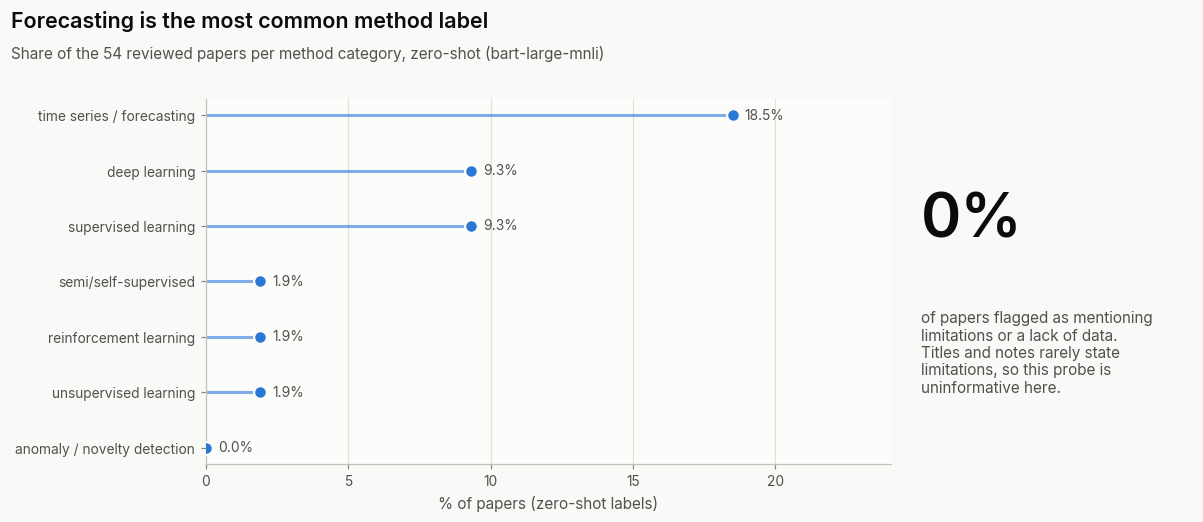


category share (zero-shot):


,category,n_papers,percent,desc
4,time series / forecasting,10,18.5,"temporal forecasting, time-series models, arim..."
1,supervised learning,5,9.3,classification or regression with labeled data
5,deep learning,5,9.3,"neural networks such as cnn, rnn, transformers"
0,unsupervised learning,1,1.9,"clustering, dimensionality reduction, anomaly ..."
2,reinforcement learning,1,1.9,"agents learning actions via rewards, rl, q-lea..."
3,semi/self-supervised,1,1.9,"semi-supervised, self-supervised, contrastive ..."
6,anomaly / novelty detection,0,0.0,detecting anomalies or outliers or rare events


 • 18% of papers dealt with time series / forecasting.
 • 9.3% of papers dealt with supervised learning.
 • 9.3% of papers dealt with deep learning.
 • 1.9% of papers dealt with unsupervised learning.
 • 1.9% of papers dealt with reinforcement learning.


In [10]:
# -----------------------------------------------------------------------------
# run in-place
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    # log environment to stdout for traceability.
    _log_env()

    print("starting analysis...")
    runner = Runner(
        input_csv=INPUT_CSV,
        reporter=reporter,
        threshold=THRESHOLD,
        device=DEVICE,
        batch_size=BATCH_SIZE,
        max_chars=MAX_CHARS,
    )
    summary = runner.run()
    reporter.save_table(summary["category_share"], "category_share")
    # one boolean column per category, named as a slug (e.g. 'time_series_forecasting')
    paper_labels = summary["paper_labels"].rename(columns=lambda c: re.sub(r"[^a-z0-9]+", "_", c.lower()).strip("_"))
    paper_labels.index.name = "paper"
    reporter.save_table(paper_labels, "paper_labels", index=True)

### Descriptive bibliometrics (hand-coded table)

Counts straight from the literature table: publication year, theme, region, dataset and peer review.


54 papers, published 2003–2025; peer-reviewed: 52


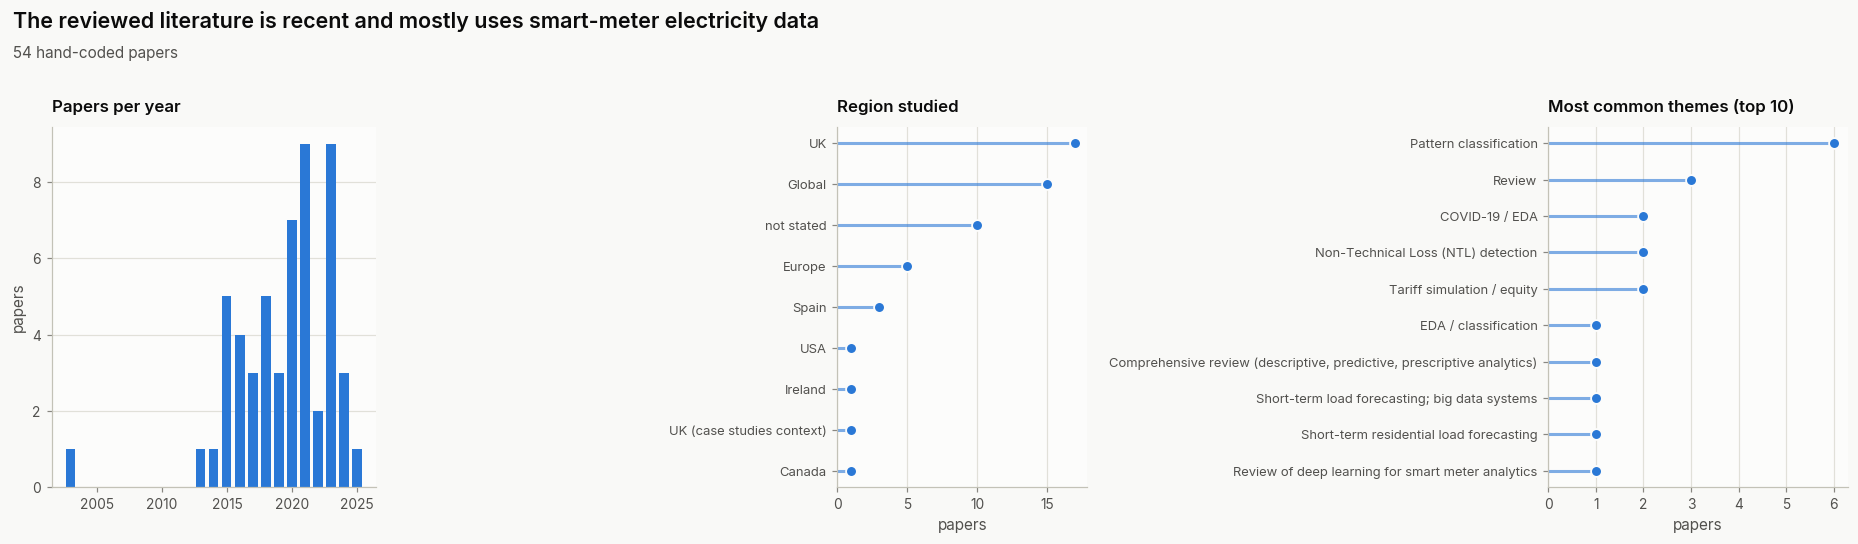


Datasets (top 8):
Dataset
Smart meter electricity                                         16
not stated                                                       4
Various public & proprietary datasets                            2
Smart meter electricity (household)                              2
Smart meter + weather data                                       1
Endesa smart meter data                                          1
Real household smart meter time series                           1
Residential smart meter datasets (non-shared across clients)     1


In [11]:
papers = pd.read_csv(INPUT_CSV).dropna(how="all").reset_index(drop=True)
papers.columns = [c.strip() for c in papers.columns]
papers = papers.replace("‑", "-", regex=True)   # non-breaking hyphens in the table -> plain hyphens
print(f"{len(papers)} papers, published {int(papers['Year'].min())}–{int(papers['Year'].max())}; "
      f"peer-reviewed: {(papers['PeerReviewed'] == 'Yes').sum()}")

c = plots.CATEGORICAL[0]
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.3, 1, 1.2]})
years = papers["Year"].astype(int).value_counts().sort_index()
ax = axes[0]
ax.bar(years.index, years.values, color=c, width=0.7)
ax.set_title("Papers per year", loc="left", fontsize=11); ax.grid(axis="x", visible=False); ax.set_ylabel("papers")
for ax, series, title in ((axes[1], papers["Region"].replace("—", "not stated").value_counts(), "Region studied"),
                          (axes[2], papers["Theme"].value_counts().head(10), "Most common themes (top 10)")):
    s = series.iloc[::-1]
    ax.hlines(range(len(s)), 0, s.values, color=c, lw=2, alpha=0.6)
    ax.scatter(s.values, range(len(s)), color=c, s=50, zorder=3, edgecolor=COLORS["surface"], linewidth=1.2)
    ax.set_yticks(range(len(s)), s.index, fontsize=8.5); ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=11); ax.set_xlabel("papers"); ax.set_xlim(left=0)
plots.figure_title(fig, "The reviewed literature is recent and mostly uses smart-meter electricity data",
                   f"{len(papers)} hand-coded papers")
reporter.save_fig(fig, "literature-descriptives")
plt.show()
print("\nDatasets (top 8):")
print(papers["Dataset"].replace("—", "not stated").value_counts().head(8).to_string())

### Checking the zero-shot labels against hand coding

The model saw only each paper's title, notes and dataset description. The hand-coded `Methods` and `Theme` columns are mapped to the same categories with keywords, and the model's labels are compared with them. Precision = share of the model's labels that the hand coding agrees with; recall = share of hand-coded papers the model found.


                   category  hand-coded  model  both  precision  recall  agreement %
      unsupervised learning          15      1     1        1.0    0.07        74.07
        supervised learning          20      5     3        0.6    0.15        64.81
     reinforcement learning           0      1     0        0.0     NaN        98.15
       semi/self-supervised           0      1     0        0.0     NaN        98.15
  time series / forecasting          15     10     6        0.6    0.40        75.93
              deep learning           7      5     4        0.8    0.57        92.59
anomaly / novelty detection           2      0     0        NaN    0.00        96.30


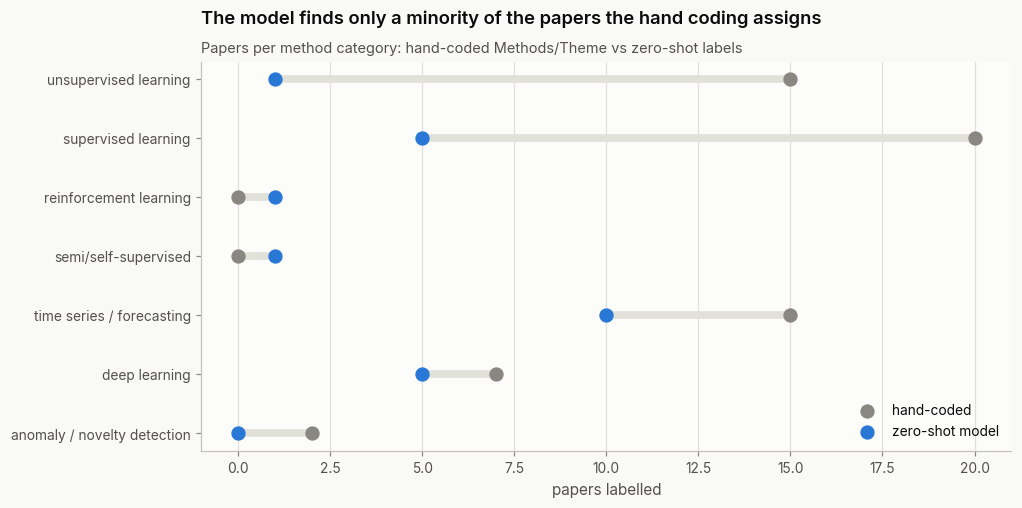

In [12]:
KEYWORDS = {
    "unsupervised learning": r"cluster|k-means|archetype|unsupervised|pca|self-organi",
    "supervised learning": r"supervised|classif|regression|random forest|svm|xgboost|gradient boost|decision tree",
    "reinforcement learning": r"reinforcement",
    "semi/self-supervised": r"semi-supervised|self-supervised|contrastive",
    "time series / forecasting": r"forecast|time.series|arima|lstm|temporal",
    "deep learning": r"deep|neural|lstm|cnn|rnn|transformer|autoencoder",
    "anomaly / novelty detection": r"anomal|outlier|fraud|theft|non-technical|ntl",
}
hand_text = (papers["Methods"].fillna("") + " " + papers["Theme"].fillna("")).str.lower()
labels = summary["paper_labels"]
rows = []
for cat, pattern in KEYWORDS.items():
    hand = hand_text.str.contains(pattern, regex=True)
    model = labels[cat]
    both = int((hand & model).sum())
    rows.append({"category": cat, "hand-coded": int(hand.sum()), "model": int(model.sum()), "both": both,
                 "precision": both / model.sum() if model.sum() else np.nan,
                 "recall": both / hand.sum() if hand.sum() else np.nan,
                 "agreement %": 100 * (hand == model).mean()})
validation = pd.DataFrame(rows)
print(validation.round(2).to_string(index=False))
reporter.save_table(snake_columns(validation), "label_validation")

v = validation.iloc[::-1]
pos = range(len(v))
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.hlines(pos, v["model"], v["hand-coded"], color=COLORS["grid"], lw=5)
ax.scatter(v["hand-coded"], pos, color=INK["muted"], s=70, zorder=3, label="hand-coded")
ax.scatter(v["model"], pos, color=plots.CATEGORICAL[0], s=70, zorder=3, label="zero-shot model")
ax.set_yticks(list(pos), v["category"]); ax.grid(axis="y", visible=False); ax.set_xlabel("papers labelled")
ax.legend(loc="lower right")
plots.title(ax, "The model finds only a minority of the papers the hand coding assigns",
            "Papers per method category: hand-coded Methods/Theme vs zero-shot labels")
reporter.save_fig(fig, "zero-shot-vs-hand-coded")
plt.show()

## Conclusions

**Reading the validation:** precision is reasonable where the model does assign a label, but recall is low: it finds only a minority of the papers the hand coding assigns to each method (see `recall`). The zero-shot shares therefore understate how often each method appears. For the write-up, the hand-coded `Methods` and `Theme` columns are the more reliable source, and the model's labels are best treated as an independent, conservative check.


## Limitations
- The literature table is small (54 papers) and hand-compiled, so shares describe this review rather than the whole field.
- The model reads short texts (title, notes, dataset), not abstracts, with a fixed 0.5 threshold. The agreement table above shows where its labels can and cannot be trusted.
- "Mentions limitations or lack" is judged from the same short texts, so it under-counts limitations that only appear in the full paper.

## Future work
- Add abstracts (e.g. from Scopus or Web of Science exports) to give the classifier more to work with.
- Add publication-trend and citation analysis from those exports.
